# Single temperature plot:

In [1]:
import qutip as qt
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#Define variables:
theta_list = np.array([np.pi, np.pi/3])
tlist = np.linspace(0, 10, 500)
phis = np.zeros(len(theta_list))*0 #Phi is unimportant in this case:
#Hilbert space dimension:
N = 2

#Constants:
w = 1
w_k = 1 #Thermal bath frequency:
T = 0.01 #temperature (K)
gamma = 1

#Creatrion/annihilation operator:
sigma = qt.destroy(N)
sigma_dag = sigma.dag()


#Hamiltonian:

Ham = w*sigma_dag*sigma



#Collapse operators:
N_T = 1 / (np.exp(w_k / T) - 1) #Assuming hbar, K_b = 1 

c_ops = [(np.sqrt(gamma*(N_T+1))*sigma), 
         (np.sqrt(gamma*(N_T))*sigma.dag())] 



#Ground state:
ground = qt.basis(2,0) * qt.basis(2,0).dag() #Evolved state

#Empty list for rho:
rho_list = []


#Initial conditions:
x,y,z = [],[],[]

for theta, phi in zip(theta_list, phis):
    x.append(np.sin(theta) * np.cos(phi))
    y.append(np.sin(theta) * np.sin(phi))
    z.append(np.cos(theta))
    

    
rho_0_list = []
for xi, yi, zi in zip(x, y, z):
    rho = (1/2)*(qt.qeye(N) + xi*qt.sigmax() + yi*qt.sigmay() + zi*qt.sigmaz())
    rho_0_list.append(rho)

In [3]:
#Solver:
results = [qt.mesolve(Ham,rho,tlist,c_ops) for rho in rho_0_list]

#states:
all_rho_t = [res.states for res in results]

#Calculate the trace distances to plot:
Dist = []


for rho_t in all_rho_t: #Loops over A   
    D_t = [qt.tracedist(rho, ground) for rho in rho_t]
    Dist.append(D_t)

Dist = np.array(Dist)

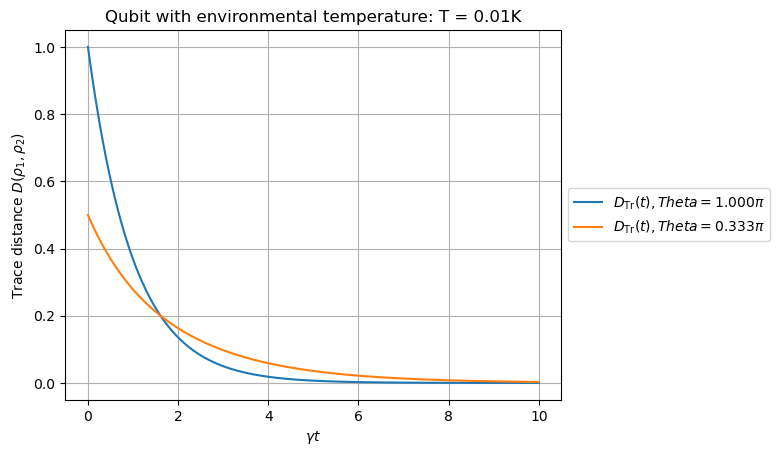

In [4]:
fig, ax = plt.subplots()



ax.plot(tlist, Dist[0],label=rf"$D_{{\rm Tr}}(t), Theta={theta_list[0]/np.pi:.3f}\pi$")

ax.plot(tlist, Dist[1], label=rf"$D_{{\rm Tr}}(t), Theta={theta_list[1]/np.pi:.3f}\pi$")

ax.set_title(f'Qubit with environmental temperature: T = {T}K')
ax.set_xlabel('$\gamma t$')
ax.set_ylabel("Trace distance $D(\\rho_1, \\rho_2)$")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.grid(True)